## Integrated CA2 Ciaran Lynch sba26096

### Introduction

Ths is an integrated CA2 assignment, for the subjects of:  
1.  Data Preparation  
2.  Statistical Techniques for DA  
3.  Machine Learning  

Background:

Suppose you are working as a Data Analyst or Data Scientist at a Renewable Energy Market and Grid Planning Consultancy in Ireland. The company has provided you with a synthetic dataset containing projected solar photovoltaic (PV) demand observations across Irish counties for the future planning period 2027 -2034. This reflects Ireland's continued expansion of solar PV and the need to understand where future installation demand may be strongest.
The dataset includes economic, market, technical, infrastructure, and policy-related indicators, such as average household income, electricity price levels, solar irradiance, roof suitability, grid accessibility, synthetic SEAI grant support, installation cost levels, planning constraints, customer segment, and forecast year.
It also includes
●	The Solar PV Demand Level (Low, Average, High)
●	The Projected Annual Solar PV Demand (kWp) for each observation

We have been provided with an excel file called CA2_dataset.  For the purpose of uploading to Python, I will create a csv version 

We also have a Data Dictionary called: Data Dictionary - Solar Panels. I created a csv version and I will Read this into Python as CA2_Data_DIctionary.csv  

From the information received in the data Dictionary, the Solar_PV_Demand_Level should have 3 categories: Low, Average, High.  This variable will be treated as the Target Variable for this project, in terms of Machine Learning.

There are three columns that shoul be Categorical and therefore an Object / String for Python analysis:
1. County
2. Customer_Segment
3. Solar_PV_Demand_Level

All other columns need to be either Integer or Float as they have numeric values.  The first steps will be:  

A. Add Python Libraries  

B. Read in the Data_Dictionary csv file, to show expected values for each column  

C. Read in the CA2_Dataset csv file, to check how each columns current values




Add Python Libraries

In [187]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np

Open the Data Dictionary csv version

In [188]:
df_Dict = pd.read_csv("CA2_Data_Dictionary.csv")

In [189]:
df_Dict

,Variable,Data Type,Unit,Description,Expected Values / Range
0,County,Categorical,NaN,Irish county associated with the prospective s...,26 counties of the Republic of Ireland
1,Forecast_Year,Integer,Year,Future planning year for the synthetic solar P...,2027 - 2034
2,Local_Mean_Household_Disposable_Income_EUR,Numeric,EUR/year,Synthetic estimate of mean annual disposable h...,"Typically EUR 35,000 - 125,000"
3,Electricity_Cost_Index,Numeric,Index,Synthetic electricity-cost pressure index for ...,Typically 65 - 150; 100 = scenario baseline
4,Solar_Resource_Index,Numeric,Score,Relative solar-resource potential for the obse...,1 - 10; higher = stronger solar resource
5,Site_Suitability_Score,Numeric,Score,Suitability of the prospective site for solar ...,1 - 10; higher = more suitable
6,Grid_Connection_Accessibility_Score,Numeric,Score,Relative ease of electricity-network access or...,1 - 10; higher = easier access or connection
7,Scenario_Grant_Support_EUR,Numeric,EUR,Synthetic future grant or support amount used ...,Non-negative EUR; varies by customer segment
8,Installation_Cost_Index,Numeric,Index,Relative solar PV installation-cost index. A v...,Typically 55 - 145; 100 = scenario baseline
9,Planning_and_Site_Constraint_Index,Numeric,Score,"Synthetic constraint index covering planning, ...",1 - 10; higher = stronger constraints


In [190]:
df = pd.read_csv("CA2_Dataset.csv")

In [191]:
df.head(5)

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp
0,Cork,2028.0,"€65,862.18",89.99,8.13,5.61,8.08,"€1,908.61",81.96,5.67,Residential,High,8.45
1,Mayo,2031.0,"€67,500.75",84.20,4.81,7.66,5.06,"€15,663.54",113.48,1.96,SME,Average,101.80
2,Laois,2030.0,"€79,701.35",111.98,6.75,5.95,8.89,"€1,649.07",99.59,4.12,Residential,Average,4.70
3,Kildare,2033.0,"€87,871.20",101.35,7.28,5.15,6.05,"€1,266.87",98.49,6.65,Residential,Average,10.30
4,Dublin,2030.0,"€105,318.63",98.78,6.88,9.11,9.47,"€8,999.65",100.10,7.37,SME,High,150.00


In [192]:
df.tail(5)

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp
2075,Dublin,2032.0,"€109,767.78",128.31,7.14,6.23,7.57,"€1,323.28",89.34,6.00,Residential,High,9.59
2076,Dublin,2030.0,"€88,591.06",108.95,6.60,6.44,8.47,"€1,327.34",90.11,7.84,Residential,Average,7.97
2077,Meath,2034.0,"€91,467.03",94.46,6.98,5.70,7.43,"€1,293.27",78.95,4.28,Residential,High,10.46
2078,Cork,2030.0,"€83,959.35",92.18,5.51,5.00,8.70,"€1,432.16",97.46,6.56,Residential,Average,10.59
2079,Cork,2033.0,"€78,352.80",99.88,8.37,2.63,8.29,"€1,596.02",82.04,6.78,Residential,Average,9.60


In [193]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2080 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   County                                        2059 non-null   str    
 1   Forecast_Year                                 2059 non-null   float64
 2   Local_Mean_Household_Disposable_Income_EUR    2059 non-null   str    
 3   Electricity_Cost_Index                        2059 non-null   float64
 4   Solar_Resource_Index                          2059 non-null   float64
 5   Site_Suitability_Score                        2059 non-null   float64
 6   Grid_Connection_Accessibility_Score           2059 non-null   float64
 7   Scenario_Grant_Support_EUR                    2059 non-null   str    
 8   Installation_Cost_Index                       2059 non-null   float64
 9   Planning_and_Site_Constraint_Index            2059 non-null   float64
 10 

On review of the loaded data:

Forecast_Year is listed as a float, as this value does not need decimal points, it be converted to an Integer.  
    
Local_Mean_Household_Disposable_Income_EUR is currently listed as a strng, as it has numeric values with decimal points, it need to be converted to a Float.  

Scenario_Grant_Support_EUR is is currently listed as a strng, as it has numeric values with decimal points, it need to be converted to a Float.   

After reviewing, i was unable to apply the .apply(pd.to_numeric, errors="coerce").astype(float) methods on Local_Mean_Household_Disposable_Income_EUR and Scenario_Grant_Support_EUR.  
    
Both of these were listed as strings and had "€" symbol and "," symbols inside the string value, that needed to be removed.  
In order to fix the issues, i had to run a str.replace for the "€" and "," symbols, before converting to floats.  See code listed below

## Data Preparation

In [194]:
df["Forecast_Year"] = df["Forecast_Year"].apply(pd.to_numeric, errors="coerce").astype("Int64")

In [195]:
df["Local_Mean_Household_Disposable_Income_EUR"] = (
    df["Local_Mean_Household_Disposable_Income_EUR"].str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False).astype(float)
)

In [196]:
df["Scenario_Grant_Support_EUR"] = (
    df["Scenario_Grant_Support_EUR"].str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False).astype(float)
)

In [197]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2080 entries, 0 to 2079
Data columns (total 13 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   County                                        2059 non-null   str    
 1   Forecast_Year                                 2059 non-null   Int64  
 2   Local_Mean_Household_Disposable_Income_EUR    2059 non-null   float64
 3   Electricity_Cost_Index                        2059 non-null   float64
 4   Solar_Resource_Index                          2059 non-null   float64
 5   Site_Suitability_Score                        2059 non-null   float64
 6   Grid_Connection_Accessibility_Score           2059 non-null   float64
 7   Scenario_Grant_Support_EUR                    2059 non-null   float64
 8   Installation_Cost_Index                       2059 non-null   float64
 9   Planning_and_Site_Constraint_Index            2059 non-null   float64
 10 

All values are now currently set up in their correct format.

I will carry out analysis of each column, to check for:

1. Mispelling of String values  
2. Missing rows of data
3. Out of Range values

However the first step will be to check for duplicates and remove

Check for duplicates and remove

In [198]:
df.shape

(2080, 13)

In [199]:
duplicateRows = df[df.duplicated()]
print("The number of duplicate rows = ", len(duplicateRows))

The number of duplicate rows =  10


In [200]:
df.drop_duplicates(inplace = True) 

In [201]:
df.shape

(2070, 13)

In [202]:
Original_Shape = len(df["County"])

Original_Shape

2070

### Carry out Analysis of each Column

Begin with the String Values  

1. Solar_PV_Demand_Level  
2. Customer_Segment  
3. County


In [203]:
df.isnull().sum()

County                                          21
Forecast_Year                                   21
Local_Mean_Household_Disposable_Income_EUR      21
Electricity_Cost_Index                          21
Solar_Resource_Index                            21
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                21
Solar_PV_Demand_Level                           21
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

Notice all columns have 21 missing rows of data

1. Carry Out Analysis of Solar_PV_Demand_Level  

Per dictionary, this is the Target variable and should have 3 categories of:
    Low
    Average
    High

In [204]:
df["Solar_PV_Demand_Level"].unique()

<ArrowStringArray>
['High', 'Average', 'Low', 'Medium', nan, 'NONE', 'Very High', 'high']
Length: 8, dtype: str

In [205]:
print(df["Solar_PV_Demand_Level"].value_counts(dropna=False))

Solar_PV_Demand_Level
Average      983
Low          533
High         529
NaN           21
Medium         1
NONE           1
Very High      1
high           1
Name: count, dtype: int64


In [206]:
df["Solar_PV_Demand_Level"] = df["Solar_PV_Demand_Level"].replace(
    {
        "Medium": "Average",
        "Very High": "High",
        "high" : "High",
        "NONE" : np.nan,        
    }
)

In [207]:
df.isnull().sum()

County                                          21
Forecast_Year                                   21
Local_Mean_Household_Disposable_Income_EUR      21
Electricity_Cost_Index                          21
Solar_Resource_Index                            21
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                21
Solar_PV_Demand_Level                           22
Projected_Solar_PV_Installation_Capacity_kWp    21
dtype: int64

The categorical values of the Solar_PV_Demand_Level have been replaced and the NONE value was converted to nan using numpy.  
    
    This has now left 22 missing values


In [208]:
print(df["Solar_PV_Demand_Level"].value_counts(dropna=False))

Solar_PV_Demand_Level
Average    984
Low        533
High       531
NaN         22
Name: count, dtype: int64


In [209]:
df.loc[
    df["Solar_PV_Demand_Level"].isna(),
    ["Solar_PV_Demand_Level", "County", "Forecast_Year", "Electricity_Cost_Index", "Customer_Segment", "Local_Mean_Household_Disposable_Income_EUR"]
    ]

,Solar_PV_Demand_Level,County,Forecast_Year,Electricity_Cost_Index,Customer_Segment,Local_Mean_Household_Disposable_Income_EUR
158,NaN,Limerick,2022,108.42,Residential,61922.10
161,NaN,Cork,2032,120.62,Residential,80616.04
277,NaN,Roscommon,2033,112.23,SME,63802.98
674,NaN,Wicklow,2028,107.31,Farm,84490.97
707,NaN,Cork,2033,99.00,Residential,84677.02
791,NaN,Cork,2028,112.49,SME,69257.98
1004,NaN,Monaghan,2028,101.85,Residential,58980.17
1011,NaN,Cork,2029,111.84,Residential,49549.08
1140,NaN,Dublin,2034,87.95,SME,104812.38
1346,NaN,Dublin,2028,93.06,Residential,87221.92


In [210]:
df.loc[
    df["Solar_PV_Demand_Level"] == "Average",
    "Electricity_Cost_Index"].median()

np.float64(103.42)

In [211]:
df.loc[
    df["Solar_PV_Demand_Level"] == "High",
    "Electricity_Cost_Index"].median()

np.float64(106.775)

source  https://www.kdnuggets.com/masked-arrays-in-numpy-to-handle-missing-data.  

As Solar_PV_Demand_Level is the Target variable, i will not drop any values.  Values will be imputed on a rule based approach
    
Create a mask for the missing values for Solar_PV_Demand_Level
I will take the median values based on Electricity_Cost_Index and impute a value for Solar_PV_Demand_Level, based on either High, Average or Low

In [212]:
mask = df["Solar_PV_Demand_Level"].isna()

High = df.loc[
    df["Solar_PV_Demand_Level"] == "High",
    "Electricity_Cost_Index"].median()

Average = df.loc[
    df["Solar_PV_Demand_Level"] == "Average",
    "Electricity_Cost_Index"].median()

df.loc[mask, "Solar_PV_Demand_Level"] = np.select(
    [
        df.loc[mask, "Electricity_Cost_Index"] >= High,
        df.loc[mask, "Electricity_Cost_Index"] >= Average

    ] ,
    [
        "High",
        "Average"
    ], default = "Low"  

)


In [213]:
df.loc[
    df["Solar_PV_Demand_Level"].isna(),
    ["Solar_PV_Demand_Level", "County", "Forecast_Year", "Electricity_Cost_Index", "Customer_Segment", "Local_Mean_Household_Disposable_Income_EUR"]
    ]

,Solar_PV_Demand_Level,County,Forecast_Year,Electricity_Cost_Index,Customer_Segment,Local_Mean_Household_Disposable_Income_EUR


In [214]:
# Spot check to see if the record updated correctly
df.loc[ [791,1471, 2055], ["Solar_PV_Demand_Level", "Electricity_Cost_Index", "County", "Forecast_Year"] ]

,Solar_PV_Demand_Level,Electricity_Cost_Index,County,Forecast_Year
791,High,112.49,Cork,2028
1471,Low,101.73,Wicklow,2029
2055,Low,94.93,Kildare,2032


Analysis of Solar_PV_Demand_Level.  

On review of the Solar_PV_Demand_Level column, it was discovered that we had 22 missing rows after replacing incorrect values.  
In order to impute values, I searched for the median High value and median Average value of the Electricity_Cost_Index.  

The variable "High" had a median value of 106.77 or greater,  

The "Average" variable had a value of 103.44 or higher, with the default being set as "Low".  

The above formula assigned a value to Solar_PV_Demand_Level, based on the median value of that rows Electricity_Cost_Index. 

The values were imputed as either High, Average or Low.  

I beleive this was an appropriate approach, rather than deleting 22 valuable rows of data, in order to retain as much data as possible.  
 

Next I will create a target_map and assign impute numeric values to the Solar_PV_Demand_Level:

High = 0,
Average =  1,
Low = 2


In [215]:
target_map = {
        "High"  : 2,
        "Average" : 1,
        "Low" : 0
   
    }

In [216]:
df["PV_Demand_Code"] = df["Solar_PV_Demand_Level"].map(target_map)

In [217]:
df["PV_Demand_Code"].value_counts()

PV_Demand_Code
1    984
0    545
2    541
Name: count, dtype: int64

*****

2. Carry out analysis of Customer_Segment  

Per Dictionary, values should be  
1. Residential, 
2. SME, 
3. Farm, 
4. Public/Community

In [218]:
df["Customer_Segment"].unique()

<ArrowStringArray>
[     'Residential',              'SME',             'Farm',
                nan, 'Public/Community',        'Household',
           'Public',    'Farm Business',       'Industrial']
Length: 9, dtype: str

In [219]:
print(df["Customer_Segment"].value_counts(dropna=False))

Customer_Segment
Residential         1034
SME                  517
Farm                 320
Public/Community     174
NaN                   21
Household              1
Public                 1
Farm Business          1
Industrial             1
Name: count, dtype: int64


In [220]:
df["Customer_Segment"] = df["Customer_Segment"].replace(
    {
        "Farm Business": "Farm",
        "Public": "Public/Community",
        "Household" : "Residential",
        "Industrial": "SME"      
    }
)

In [221]:
print(df["Customer_Segment"].value_counts(dropna=False))

Customer_Segment
Residential         1035
SME                  518
Farm                 321
Public/Community     175
NaN                   21
Name: count, dtype: int64


In [222]:
# Show the missing values for Customer_Segment
df.loc[
    df["Customer_Segment"].isna(),
    ["County", 
     "Scenario_Grant_Support_EUR",
    "Forecast_Year"]
    ]

,County,Scenario_Grant_Support_EUR,Forecast_Year
25,Tipperary,898.03,2034
91,Wexford,1543.01,2031
219,Donegal,7509.67,2027
238,Donegal,1540.67,2029
350,Meath,1238.53,2029
415,Kerry,1799.92,2028
734,Tipperary,1151.69,2034
751,Donegal,18085.19,2030
790,Mayo,13434.06,2027
811,Carlow,1454.19,2027


Create a Map of Scenario_Grant_Support_EUR values to impute to Customer_Segment.

In [223]:
#  Show the groupBy for Scenario_Grant_Support_EUR & Customer_Segment 
Customer_Medians = (
    df.groupby(["Customer_Segment"]
    )["Scenario_Grant_Support_EUR"].median().round(2)
)

print(Customer_Medians)

Customer_Segment
Farm                15132.77
Public/Community    17434.89
Residential          1441.34
SME                 12040.94
Name: Scenario_Grant_Support_EUR, dtype: float64


From the data dictionary, it states that Grant Support is based on the Customer Segment.  Therefore, it is appropriate to impute median values per Scenario_Grant_Support_EUR, grouped by Customer_Segment.   

For Example a Grant support for Residential grant is €1,441, whereas for a Farm Grant it is €15,132

Figures are approximately based on the median values of Grant Support per Segment.  
    
The map below, will impute the blank Customer Segment as:  

1. Grant Supports of Where 17000 and above are assigned to "Public/Community", 

2. Grant Supports of 15000 and above are assigned to "Farm", 

3. Grant Support of 12000 and above are assigned to "SME" 

4. otherwise blank Customer Segments will be imputed as "Residential"

In [224]:
customer_mask = df["Customer_Segment"].isna()


df.loc[customer_mask, "Customer_Segment"] = np.select(
    [
        df.loc[customer_mask, "Scenario_Grant_Support_EUR"] >= 17000,
        df.loc[customer_mask, "Scenario_Grant_Support_EUR"] >= 15000,
        df.loc[customer_mask, "Scenario_Grant_Support_EUR"] >= 12000

    ] ,
    [
        "Public/Community",
        "Farm",
        "SME"
        ], default = "Residential"  

)

In [225]:
# check to see if the record updated correctly, use Boundary Value Analysis to find values for each Segment
df.loc[ [25, 1341, 1373, 751], ["Scenario_Grant_Support_EUR", "Customer_Segment", "Forecast_Year"] ]

,Scenario_Grant_Support_EUR,Customer_Segment,Forecast_Year
25,898.03,Residential,2034
1341,16158.05,Farm,2031
1373,11210.99,Residential,2034
751,18085.19,Public/Community,2030


In [226]:
print(df["Customer_Segment"].value_counts(dropna=False))

Customer_Segment
Residential         1051
SME                  521
Farm                 322
Public/Community     176
Name: count, dtype: int64


Twenty One missing values for Customer_Segment were identified.  
    
As this is an important column in the analysis, data was imputed base on the median Scenario_Grant_Support_Eur values.  

  
The values were mapped to the Customer_Segment based on a rules based approach

****

3. Carry out analysis of County Column

In [227]:
df["County"].unique()

<ArrowStringArray>
[     'Cork',      'Mayo',     'Laois',   'Kildare',    'Dublin',   'Wicklow',
     'Meath',    'Galway',   'Wexford',     'Kerry',     'Louth',     'Sligo',
  'Monaghan', 'Tipperary',         nan, 'Westmeath',   'Donegal',  'Kilkenny',
     'Cavan',  'Limerick',     'Clare',    'Carlow', 'Roscommon',  'Longford',
 'Waterford',    'Dublín',    'Wexfrd',    'Offaly',   'Leitrim',   'Co Cork',
     'Dubln']
Length: 31, dtype: str

In [228]:
df["County"] = df["County"].replace(
    {
        "Co Cork": "Cork",
        "Dublín": "Dublin",
        "Dubln" : "Dublin",
        "Wexfrd": "Wexford"
        
    }
)

In [229]:
print(df["County"].value_counts(dropna=False))

County
Dublin       524
Cork         288
Galway       110
Kildare      105
Limerick      92
Meath         81
Wexford       75
Donegal       68
Wicklow       64
Louth         59
Kerry         58
Tipperary     58
Mayo          55
Clare         55
Waterford     45
Cavan         44
Laois         43
Kilkenny      42
Carlow        36
Westmeath     32
Roscommon     28
Monaghan      23
NaN           21
Sligo         20
Longford      17
Offaly        17
Leitrim       10
Name: count, dtype: int64


In [230]:
df.loc[
    df["County"].isna(),
    ["County", 
     "Forecast_Year",
     "Local_Mean_Household_Disposable_Income_EUR",
     "Electricity_Cost_Index",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Customer_Segment
29,NaN,2029,60099.50,125.75,Public/Community
196,NaN,2034,78668.77,100.55,Public/Community
256,NaN,2031,93209.98,108.91,Residential
347,NaN,2028,63393.34,87.67,Farm
421,NaN,2030,78221.20,110.62,Residential
428,NaN,<NA>,50615.34,107.42,Farm
487,NaN,2027,80175.73,120.77,Residential
492,NaN,2027,55864.81,112.22,Residential
638,NaN,2034,96188.23,110.44,SME
658,NaN,2027,60314.95,135.19,Farm


Not sure how to approach this.  This is a string object that may not be appropriate for ML, although it is important column for analysis

For now I will fill missing values with "Unknown"

In [231]:
df["County"] = df["County"].fillna("Unknown")

In [232]:
print(df["County"].value_counts(dropna=False))

County
Dublin       524
Cork         288
Galway       110
Kildare      105
Limerick      92
Meath         81
Wexford       75
Donegal       68
Wicklow       64
Louth         59
Kerry         58
Tipperary     58
Mayo          55
Clare         55
Waterford     45
Cavan         44
Laois         43
Kilkenny      42
Carlow        36
Westmeath     32
Roscommon     28
Monaghan      23
Unknown       21
Sligo         20
Longford      17
Offaly        17
Leitrim       10
Name: count, dtype: int64


***

#### Continue Analysis of each Column

Working on Numeric Values  

4. Forecast_Year  
5. Local_Mean_Household_Disposable_Income_EUR  
6. Electricity_Cost_Index
7.
8.
        


4. Carry out Analysis of Forecast_Years

In [233]:
df["Forecast_Year"].unique()

<IntegerArray>
[2028, 2031, 2030, 2033, 2029, 2027, 2034, 2032, <NA>, 2022, 2045, 9999, 2055]
Length: 13, dtype: Int64

In [234]:
print(df["Forecast_Year"].value_counts(dropna=False))

Forecast_Year
2030    292
2033    270
2028    265
2029    249
2031    248
2034    246
2032    244
2027    231
<NA>     21
2022      1
2045      1
9999      1
2055      1
Name: count, dtype: Int64


In [235]:
Invalid_Years = df.loc[
    (df["Forecast_Year"] < 2027) | 
    (df["Forecast_Year"] > 2034)
    ]

print(Invalid_Years[ ["County", "Forecast_Year"] ])

        County  Forecast_Year
158   Limerick           2022
262     Dublin           2045
768     Dublin           9999
2041      Cork           2055


We have some incorrect data, with some years listed as outside the scope of 2027-2034.  
    

In [236]:
df = df.drop(
        df.loc[
            (df["Forecast_Year"] < 2027) | 
            (df["Forecast_Year"] > 2034)
        ].index
)

In [237]:
df = df.dropna(subset=["Forecast_Year"])

Four records contained years outside the documented range of 2027-2034.  

As the correct year could not be inferred, these four observations were removed from the dataset.

21 missing values were also observed for Forecast_Year.  As the correct year could not be reliably inferred, these records were also removed from the dataset, to preserve quality

In [238]:
df["Forecast_Year"].value_counts().sort_index()

Forecast_Year
2027    231
2028    265
2029    249
2030    292
2031    248
2032    244
2033    270
2034    246
Name: count, dtype: Int64

In [239]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR      21
Electricity_Cost_Index                          21
Solar_Resource_Index                            20
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
PV_Demand_Code                                   0
dtype: int64

****

5. Carry out analysis of Household Disposable Income.

This is a value that I could impute median values per county

In [240]:
df.loc[
    df["Local_Mean_Household_Disposable_Income_EUR"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
324,Wicklow,2034,NaN,69.43,6.81,6.26,6.73,1587.29,76.59,7.83,Residential,Average,9.16,1
339,Kildare,2028,NaN,115.53,7.06,9.13,7.67,11517.15,88.86,5.20,SME,High,NaN,2
353,Dublin,2034,NaN,113.12,8.00,3.95,8.87,1324.68,84.87,6.53,Residential,Average,14.80,1
363,Dublin,2030,NaN,114.09,6.58,6.55,9.21,1852.79,103.30,5.90,Residential,Average,4.63,1
470,Dublin,2032,NaN,103.16,5.99,7.90,10.00,17795.14,73.79,8.34,Farm,High,230.16,2
573,Galway,2030,NaN,87.49,6.87,6.56,7.44,1340.08,107.28,5.19,Residential,Average,8.81,1
639,Cork,2027,NaN,102.43,7.65,6.10,8.89,6960.71,113.11,4.70,SME,Average,98.98,1
650,Westmeath,2028,NaN,102.00,5.75,4.38,6.75,1505.12,119.54,5.13,Residential,Low,6.06,0
783,Kerry,2031,NaN,97.12,5.31,7.98,NaN,20114.82,103.26,4.92,SME,Low,77.98,0
896,Kerry,2027,NaN,132.08,5.65,7.34,4.99,31925.30,94.29,4.72,Farm,Average,96.13,1


For the Local_Mean_Household_Disposable_Income_EUR variable, I will impute the median value per County

Create a Groupby per county and find the median household income. I will call this "county_medians" and fill missing values by mapping in county_medians

In [241]:
county_Income_medians = df.groupby("County")[
    "Local_Mean_Household_Disposable_Income_EUR"].median().round(2)

print(county_Income_medians)

County
Carlow       64284.62
Cavan        60771.95
Clare        66784.67
Cork         74218.60
Donegal      57524.76
Dublin       92328.99
Galway       71806.58
Kerry        64705.53
Kildare      85623.65
Kilkenny     67840.69
Laois        68182.57
Leitrim      55499.46
Limerick     70107.52
Longford     64322.14
Louth        68684.49
Mayo         59810.26
Meath        80188.47
Monaghan     63454.10
Offaly       66475.00
Roscommon    59886.56
Sligo        64476.37
Tipperary    63914.94
Unknown      70223.95
Waterford    69197.20
Westmeath    70689.98
Wexford      67471.93
Wicklow      85573.74
Name: Local_Mean_Household_Disposable_Income_EUR, dtype: float64


In [242]:
df["Local_Mean_Household_Disposable_Income_EUR"] = (
    df["Local_Mean_Household_Disposable_Income_EUR"].fillna(df["County"].map(county_Income_medians) )
)

In [243]:
# spot check to see if the record updated correctly
df.loc[ [783, 470, 650], ["Local_Mean_Household_Disposable_Income_EUR", "County", "Forecast_Year"] ]

,Local_Mean_Household_Disposable_Income_EUR,County,Forecast_Year
783,64705.53,Kerry,2031
470,92328.99,Dublin,2032
650,70689.98,Westmeath,2028


In [244]:
df.loc[
    df["Local_Mean_Household_Disposable_Income_EUR"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code


In [245]:
df.describe()

,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
count,2045.0,2045.000000,2024.000000,2025.000000,2024.000000,2024.000000,2024.000000,2024.000000,2024.000000,2024.000000,2045.000000
mean,2030.517359,76111.782641,103.642584,6.621195,6.863256,7.389264,8913.568103,97.840973,5.604121,74.751008,0.997066
std,2.258993,15913.910156,13.309878,1.219979,1.415054,1.728963,11906.846614,14.273657,1.765603,97.429667,0.723516
min,2027.0,-12000.000000,15.000000,-1.200000,-2.000000,-1.000000,-500.000000,25.000000,-1.000000,-25.000000,0.000000
25%,2029.0,64873.470000,94.937500,5.810000,5.890000,6.200000,1437.225000,88.420000,4.360000,7.550000,0.000000
50%,2030.0,74850.580000,103.705000,6.630000,6.830000,7.495000,2046.700000,98.225000,5.570000,15.820000,1.000000
75%,2033.0,87285.320000,112.502500,7.440000,7.850000,8.670000,13607.257500,107.302500,6.840000,126.565000,2.000000
max,2034.0,250000.000000,220.000000,14.000000,14.200000,15.000000,240000.000000,225.000000,16.000000,2500.000000,2.000000


In order to retain data, the median household income was imputed, based on the county of origin.

See Statistics for Local_Mean_Household_Disposable_Income_EUR.  
    
We have a -€1,200 figure listed.  
I need to check any values with negatives, as the Dictionary states "Typically EUR 35,000 - 125,000"
Check any amount outside those ranges also.

In [246]:
df.loc[
    (df["Local_Mean_Household_Disposable_Income_EUR"] < 35000) | 
    (df["Local_Mean_Household_Disposable_Income_EUR"] > 125000)
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
170,Wexford,2029,180000.0,107.49,8.39,6.71,9.94,1491.07,105.82,2.83,Residential,High,9.40,2
578,Dublin,2029,-12000.0,107.12,6.48,6.56,9.76,1685.61,110.59,9.84,Residential,Low,3.95,0
1016,Meath,2029,250000.0,88.85,6.28,6.48,7.80,1485.22,99.18,5.20,Residential,Average,7.22,1
1174,Cork,2029,5000.0,97.75,7.50,5.42,7.67,1211.19,109.12,6.63,Residential,Low,4.20,0


In [247]:
df["Local_Mean_Household_Disposable_Income_EUR"] = np.where(
    (df["Local_Mean_Household_Disposable_Income_EUR"] < 35000) | 
    (df["Local_Mean_Household_Disposable_Income_EUR"] > 125000),
    df["County"].map(county_Income_medians),
    df["Local_Mean_Household_Disposable_Income_EUR"]
)

In [248]:
# check to see if the record updated correctly
df.loc[ [578, 1174, 170, 1016], ["Local_Mean_Household_Disposable_Income_EUR", "County", "Forecast_Year"] ]

,Local_Mean_Household_Disposable_Income_EUR,County,Forecast_Year
578,92328.99,Dublin,2029
1174,74218.60,Cork,2029
170,67471.93,Wexford,2029
1016,80188.47,Meath,2029


The Local_Mean_Household_Disposable_Income_EUR variable has been updated.

Missing values and out of range values were reset to the Median Household Income per county.

****

In [249]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                          21
Solar_Resource_Index                            20
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
PV_Demand_Code                                   0
dtype: int64

In [250]:
df.describe()

,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
count,2045.0,2045.000000,2024.000000,2025.000000,2024.000000,2024.000000,2024.000000,2024.000000,2024.000000,2024.000000,2045.000000
mean,2030.517359,76058.583614,103.642584,6.621195,6.863256,7.389264,8913.568103,97.840973,5.604121,74.751008,0.997066
std,2.258993,15069.145904,13.309878,1.219979,1.415054,1.728963,11906.846614,14.273657,1.765603,97.429667,0.723516
min,2027.0,35000.000000,15.000000,-1.200000,-2.000000,-1.000000,-500.000000,25.000000,-1.000000,-25.000000,0.000000
25%,2029.0,64913.280000,94.937500,5.810000,5.890000,6.200000,1437.225000,88.420000,4.360000,7.550000,0.000000
50%,2030.0,74850.580000,103.705000,6.630000,6.830000,7.495000,2046.700000,98.225000,5.570000,15.820000,1.000000
75%,2033.0,87283.490000,112.502500,7.440000,7.850000,8.670000,13607.257500,107.302500,6.840000,126.565000,2.000000
max,2034.0,116976.500000,220.000000,14.000000,14.200000,15.000000,240000.000000,225.000000,16.000000,2500.000000,2.000000


6. Carry out analysis of missing values for the Electricity_Cost_Index Variable

Again we have 21 missing rows.  Find the median cost per Customer_Segment and fill missing rows with this data

Per Dictionary of Electric_Cost. "Typically 65 - 150; 100 = scenario baseline"

Edit any out of range data to the baseline = 100

In [251]:
df.loc[
    df["Electricity_Cost_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Local_Mean_Household_Disposable_Income_EUR",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Customer_Segment
250,Wicklow,2030,92960.93,Farm
362,Cavan,2029,49799.44,SME
372,Clare,2027,57775.81,SME
444,Dublin,2032,103920.49,Residential
496,Dublin,2030,104383.79,Residential
678,Wicklow,2028,72167.98,Residential
756,Clare,2034,71274.02,SME
823,Galway,2031,74623.23,SME
834,Dublin,2032,108350.79,Residential
835,Cork,2031,79732.44,Residential


In [252]:
scenario_Baseline = 100

In [253]:
df["Electricity_Cost_Index"] = (df["Electricity_Cost_Index"].fillna( scenario_Baseline))

In [254]:
# check to see if the record updated correctly
df.loc[ [250, 444, 1837], ["Electricity_Cost_Index", "County", "Forecast_Year"] ]

,Electricity_Cost_Index,County,Forecast_Year
250,100.0,Wicklow,2030
444,100.0,Dublin,2032
1837,100.0,Clare,2034


In [255]:
df.loc[
    df["Electricity_Cost_Index"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code


In [256]:
df.loc[
     (df["Electricity_Cost_Index"] < 65) |
     (df["Electricity_Cost_Index"] > 150)
]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
26,Cork,2032,60003.07,15.0,8.09,7.05,6.59,1397.09,80.73,6.36,Residential,Average,9.29,1
338,Offaly,2032,65672.99,220.0,5.61,6.05,5.70,1221.48,87.64,1.97,Residential,Average,8.32,1
907,Carlow,2034,80301.16,185.0,7.23,3.86,NaN,544.45,75.55,5.21,Residential,Average,7.86,1
1200,Galway,2033,88297.70,35.0,NaN,10.00,5.99,6032.49,97.75,3.83,Farm,Average,122.79,1


In [257]:
df.loc[
    (df["Electricity_Cost_Index"] < 65) | 
    (df["Electricity_Cost_Index"] > 150), "Electricity_Cost_Index"
    ] = scenario_Baseline


In [258]:
# check to see if the record updated correctly
df.loc[ [26, 338, 907, 1200], ["Electricity_Cost_Index", "Customer_Segment", "Forecast_Year"] ]

,Electricity_Cost_Index,Customer_Segment,Forecast_Year
26,100.0,Residential,2032
338,100.0,Residential,2032
907,100.0,Residential,2034
1200,100.0,Farm,2033


The Electricity_Cost_Index missiing values and out of range values, were imputed to the baseline rate of 100

In [259]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                            20
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
PV_Demand_Code                                   0
dtype: int64

In [260]:
df.describe()

,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
count,2045.0,2045.000000,2045.000000,2025.000000,2024.000000,2024.000000,2024.000000,2024.000000,2024.000000,2024.000000,2045.000000
mean,2030.517359,76058.583614,103.578284,6.621195,6.863256,7.389264,8913.568103,97.840973,5.604121,74.751008,0.997066
std,2.258993,15069.145904,12.628519,1.219979,1.415054,1.728963,11906.846614,14.273657,1.765603,97.429667,0.723516
min,2027.0,35000.000000,65.000000,-1.200000,-2.000000,-1.000000,-500.000000,25.000000,-1.000000,-25.000000,0.000000
25%,2029.0,64913.280000,95.060000,5.810000,5.890000,6.200000,1437.225000,88.420000,4.360000,7.550000,0.000000
50%,2030.0,74850.580000,103.440000,6.630000,6.830000,7.495000,2046.700000,98.225000,5.570000,15.820000,1.000000
75%,2033.0,87283.490000,112.390000,7.440000,7.850000,8.670000,13607.257500,107.302500,6.840000,126.565000,2.000000
max,2034.0,116976.500000,142.620000,14.000000,14.200000,15.000000,240000.000000,225.000000,16.000000,2500.000000,2.000000


The Electricity_Cost _index has now been updated.  

Missing rows were imputed to the median rate per Customer_Segment

Out of range rows were reset to the baseline

****

7. Carry out analysis of missing values for the Solar_Resource_Index Variable

Find any missing rows and impute values based on median rate per county

Per Dictionary, the figures should be 1 - 10; higher = stronger solar resource

Find any values below out of range and impute the median values per County

In [261]:
df.loc[
    df["Solar_Resource_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Solar_Resource_Index",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Solar_Resource_Index,Customer_Segment
19,Dublin,2031,NaN,Residential
77,Cork,2029,NaN,Residential
125,Dublin,2032,NaN,SME
162,Kildare,2028,NaN,SME
184,Meath,2027,NaN,SME
261,Limerick,2030,NaN,SME
265,Meath,2027,NaN,Public/Community
332,Roscommon,2031,NaN,Farm
455,Limerick,2030,NaN,Residential
720,Louth,2028,NaN,Residential


In [262]:
SR_index_medians = df.groupby("Customer_Segment")[
    "Solar_Resource_Index"].median().round(2)

print(SR_index_medians)

Customer_Segment
Farm                6.53
Public/Community    6.56
Residential         6.63
SME                 6.71
Name: Solar_Resource_Index, dtype: float64


In [263]:
df["Solar_Resource_Index"] = (
    df["Solar_Resource_Index"].fillna(df["Customer_Segment"].map(SR_index_medians) )
)

In [264]:
# check to see if the record updated correctly
df.loc[ [77, 125, 1200], ["Solar_Resource_Index", "County", "Customer_Segment"] ]

,Solar_Resource_Index,County,Customer_Segment
77,6.63,Cork,Residential
125,6.71,Dublin,SME
1200,6.53,Galway,Farm


In [265]:
df.loc[
    df["Solar_Resource_Index"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code


In [266]:
df.loc[
     (df["Solar_Resource_Index"] < 1) |
     (df["Solar_Resource_Index"] > 10 )
 
]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
527,Limerick,2034,75455.58,89.18,0.2,8.01,7.89,22198.56,84.43,3.76,SME,High,157.27,2
1160,Cavan,2029,59005.42,108.53,11.8,7.88,6.91,1705.02,117.71,4.89,Residential,Average,6.99,1
1193,Dublin,2031,82019.75,102.94,-1.2,6.77,9.75,1596.83,92.20,5.55,Residential,High,11.89,2
1587,Galway,2032,82997.67,93.31,14.0,4.97,8.37,1727.95,97.17,6.31,Residential,Low,5.33,0


In [267]:
SR_index_medians = df.groupby("Customer_Segment")[
    "Solar_Resource_Index"].median().round(2)

print(SR_index_medians)

Customer_Segment
Farm                6.53
Public/Community    6.56
Residential         6.63
SME                 6.71
Name: Solar_Resource_Index, dtype: float64


In [268]:
df["Solar_Resource_Index"] = np.where(
    (df["Solar_Resource_Index"] < 1) | 
    (df["Solar_Resource_Index"] > 10),
    df["Customer_Segment"].map(SR_index_medians),
    df["Solar_Resource_Index"]
)

In [269]:
# check to see if the record updated correctly
df.loc[ [1193, 527, 1160, 1587], ["Solar_Resource_Index", "Customer_Segment", "Forecast_Year", "County"] ]

,Solar_Resource_Index,Customer_Segment,Forecast_Year,County
1193,6.63,Residential,2031,Dublin
527,6.71,SME,2034,Limerick
1160,6.63,Residential,2029,Cavan
1587,6.63,Residential,2032,Galway


The Solar_Resource_Index variable missing values were imputed, based on each Customer_Segment median value, in order to keep the records.  

The out of range data was also reset to the Customer_Segment median value

In [270]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                          21
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
PV_Demand_Code                                   0
dtype: int64

****

8. Carry out analysis of missing values for the Site_Suitability_Score Variable

We have 21  missing rows

Site_Suitability Score, per Dictionary should have values of "1 - 10; higher = stronger constraints"

Again from the statistics, we have out of range values to update

In [271]:
df.loc[
    df["Site_Suitability_Score"].isna(),
    ["County", 
     "Forecast_Year",
     "Site_Suitability_Score",
     "Customer_Segment"]
    ]


,County,Forecast_Year,Site_Suitability_Score,Customer_Segment
92,Meath,2028,NaN,Residential
137,Dublin,2033,NaN,Farm
233,Galway,2030,NaN,Residential
384,Cork,2031,NaN,Residential
411,Wexford,2031,NaN,Residential
534,Waterford,2027,NaN,SME
634,Cork,2030,NaN,Public/Community
677,Louth,2032,NaN,Residential
724,Cork,2032,NaN,Residential
1244,Limerick,2031,NaN,Residential


In [272]:
SS_index_medians = df.groupby("Customer_Segment")[
    "Site_Suitability_Score"].median().round(2)

print(SS_index_medians)

Customer_Segment
Farm                8.23
Public/Community    7.20
Residential         6.26
SME                 7.20
Name: Site_Suitability_Score, dtype: float64


In [273]:
df["Site_Suitability_Score"] = (
    df["Site_Suitability_Score"].fillna(df["Customer_Segment"].map(SS_index_medians) )
)

In [274]:
# check to see if the record updated correctly
df.loc[ [137, 233, 1659], ["Site_Suitability_Score", "County", "Forecast_Year"] ]

,Site_Suitability_Score,County,Forecast_Year
137,8.23,Dublin,2033
233,6.26,Galway,2030
1659,7.20,Carlow,2029


In [275]:
df.loc[
    df["Site_Suitability_Score"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code


In [276]:
df.loc[
     (df["Site_Suitability_Score"] < 1) |
     (df["Site_Suitability_Score"] > 10 )
 
]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
579,Dublin,2034,116382.38,101.36,7.67,14.2,7.93,7512.48,79.40,7.11,Farm,High,182.62,2
871,Wicklow,2030,76004.88,104.53,8.40,0.0,8.33,6988.34,121.39,5.31,SME,Average,81.36,1
953,Cork,2033,83842.41,84.86,8.07,11.5,7.29,17332.45,80.15,6.06,Public/Community,Average,178.43,1
1965,Dublin,2027,90296.41,97.52,4.91,-2.0,9.86,1770.98,108.39,6.21,Residential,Low,5.22,0


In [277]:
df["Site_Suitability_Score"] = np.where(
    (df["Site_Suitability_Score"] < 1) | 
    (df["Site_Suitability_Score"] > 10),
    df["Customer_Segment"].map(SS_index_medians),
    df["Site_Suitability_Score"]
)

In [278]:
# check to see if the record updated correctly
df.loc[ [579, 871, 953, 1965], ["Site_Suitability_Score", "Customer_Segment", "Forecast_Year", "County"] ]

,Site_Suitability_Score,Customer_Segment,Forecast_Year,County
579,8.23,Farm,2034,Dublin
871,7.20,SME,2030,Wicklow
953,7.20,Public/Community,2033,Cork
1965,6.26,Residential,2027,Dublin


The Site_Suitability_Score variable missing values were imputed, based on each Customer_Segment median value, in order to keep the records.  

The out of range data was also reset to the median value, based on Customer_Segment 

****

In [279]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score             21
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
PV_Demand_Code                                   0
dtype: int64

9. Carry out analysis of Grid_Connection_Accessibility_Score 

We have 21 missing values

Grid_Accessibility has a negative figure shown in the descriptive Statistis, per dictionary the values should be "1 - 10; higher = easier access or connection"

Find out of range values

In [280]:
df.loc[
    df["Grid_Connection_Accessibility_Score"].isna(),
    ["County", 
     "Forecast_Year",
     "Grid_Connection_Accessibility_Score",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Grid_Connection_Accessibility_Score,Customer_Segment
131,Galway,2031,NaN,Residential
174,Kerry,2033,NaN,Residential
273,Laois,2034,NaN,Residential
335,Kildare,2033,NaN,Residential
372,Clare,2027,NaN,SME
458,Wexford,2030,NaN,SME
492,Unknown,2027,NaN,Residential
552,Longford,2031,NaN,Residential
774,Cavan,2029,NaN,Farm
783,Kerry,2031,NaN,SME


In [281]:
Grid_Connection_medians = df.groupby("Customer_Segment")[
    "Grid_Connection_Accessibility_Score"].median().round(2) 

print(Grid_Connection_medians)

Customer_Segment
Farm                6.17
Public/Community    7.42
Residential         7.62
SME                 7.92
Name: Grid_Connection_Accessibility_Score, dtype: float64


In [282]:
df["Grid_Connection_Accessibility_Score"] = (
    df["Grid_Connection_Accessibility_Score"].fillna(df["Customer_Segment"].map(Grid_Connection_medians) )
)

In [283]:
# spot check to see if the record updated correctly
df.loc[ [1175, 787, 1901], ["Grid_Connection_Accessibility_Score", "Customer_Segment", "Forecast_Year"] ]

,Grid_Connection_Accessibility_Score,Customer_Segment,Forecast_Year
1175,7.62,Residential,2034
787,6.17,Farm,2028
1901,7.42,Public/Community,2032


In [284]:
df.loc[
    df["Grid_Connection_Accessibility_Score"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code


In [285]:
df.loc[
     (df["Grid_Connection_Accessibility_Score"] < 1) |
     (df["Grid_Connection_Accessibility_Score"] > 10 )
 
]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
149,Laois,2028,50305.68,109.66,5.84,4.74,15.0,1145.42,97.10,4.10,Residential,Low,4.49,0
257,Cavan,2031,58848.46,100.67,5.60,9.00,0.0,9641.06,90.95,4.12,Farm,Average,117.60,1
441,Limerick,2030,69990.11,78.09,5.98,7.97,-1.0,1515.84,111.17,6.51,Residential,Average,NaN,1
696,Donegal,2027,49458.57,98.60,4.81,7.46,12.7,15518.95,117.42,4.08,SME,Low,55.88,0


In [286]:
df["Grid_Connection_Accessibility_Score"] = np.where(
    (df["Grid_Connection_Accessibility_Score"] < 1) | 
    (df["Grid_Connection_Accessibility_Score"] > 10),
    df["Customer_Segment"].map(Grid_Connection_medians),
    df["Grid_Connection_Accessibility_Score"]
)

In [287]:
# spot check to see if the record updated correctly
df.loc[ [149, 257, 441, 696], ["Grid_Connection_Accessibility_Score", "Customer_Segment", "Forecast_Year"] ]

,Grid_Connection_Accessibility_Score,Customer_Segment,Forecast_Year
149,7.62,Residential,2028
257,6.17,Farm,2031
441,7.62,Residential,2030
696,7.92,SME,2027


The Grid_Connection_Accessibility_Score variable missing values were imputed, based on each Customer_Segment median value, in order to keep the records.  

The out of range values were also reset to the median value, based on Customer_Segment

****

In [288]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score              0
Scenario_Grant_Support_EUR                      21
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
PV_Demand_Code                                   0
dtype: int64

10.  Carry Out analysis of missing values for Scenario_Grant_Support_EUR Variable.  

The Grant levels are based on Customer_Segment, ie Farm, Public/Community, SME and Residential

Per Data Dictionary, The Scenario_Grant_Support_EUR states "Non-negative EUR; varies by customer segment"

Per statistics, we have a negative value.  There is no Max value listed in the dictionary.


In [289]:
df.loc[
    df["Scenario_Grant_Support_EUR"].isna(),
    ["County", 
     "Forecast_Year",
     "Scenario_Grant_Support_EUR",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Scenario_Grant_Support_EUR,Customer_Segment
155,Laois,2034,NaN,SME
215,Donegal,2034,NaN,Residential
225,Clare,2031,NaN,Public/Community
242,Meath,2034,NaN,Farm
288,Cork,2029,NaN,Farm
326,Dublin,2032,NaN,Public/Community
349,Dublin,2030,NaN,SME
586,Kilkenny,2030,NaN,SME
687,Roscommon,2033,NaN,SME
706,Cork,2029,NaN,Residential


In [290]:
Scenario_Grant_medians = df.groupby(
    ["Customer_Segment"]
    )["Scenario_Grant_Support_EUR"].median().round(2)

print(Scenario_Grant_medians)

Customer_Segment
Farm                15110.59
Public/Community    17690.90
Residential          1443.79
SME                 12062.78
Name: Scenario_Grant_Support_EUR, dtype: float64


In [291]:
df["Scenario_Grant_Support_EUR"] = (
    df["Scenario_Grant_Support_EUR"].fillna(df["Customer_Segment"].map(Scenario_Grant_medians) )
)

In [292]:
# check to see if the record updated correctly
df.loc[ [155, 215, 326, 242], ["Scenario_Grant_Support_EUR", "County", "Customer_Segment", "Forecast_Year"] ]

,Scenario_Grant_Support_EUR,County,Customer_Segment,Forecast_Year
155,12062.78,Laois,SME,2034
215,1443.79,Donegal,Residential,2034
326,17690.90,Dublin,Public/Community,2032
242,15110.59,Meath,Farm,2034


In [293]:
df.loc[
    df["Scenario_Grant_Support_EUR"].isna()
    ]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code


In [294]:
df.loc[df["Scenario_Grant_Support_EUR"] < 0]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
396,Meath,2032,102302.18,86.76,5.82,5.89,9.83,-500.0,80.46,5.71,SME,Average,154.12,1


In [295]:
df["Scenario_Grant_Support_EUR"] = np.where(
    (df["Scenario_Grant_Support_EUR"] < 0),
    df["Customer_Segment"].map(Scenario_Grant_medians),
    df["Scenario_Grant_Support_EUR"]
)

In [296]:
# check to see if the record updated correctly
df.loc[ [396], ["Scenario_Grant_Support_EUR", "Customer_Segment", "Forecast_Year", "County"] ]

,Scenario_Grant_Support_EUR,Customer_Segment,Forecast_Year,County
396,12062.78,SME,2032,Meath


The missing values and negative value of Scenario_Grant_Support_EUR, were updated using the median values, based on the Customer_Segment

****

In [297]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score              0
Scenario_Grant_Support_EUR                       0
Installation_Cost_Index                         21
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
PV_Demand_Code                                   0
dtype: int64

11. Carry Out analysis of Installation_Cost_Index Variable.  

We have 21 missing values
    
Installation_Cost_Index has the following values per dictionary  "Typically 55 - 145; 100 = scenario baseline"


In [298]:
df.loc[
    df["Installation_Cost_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Projected_Solar_PV_Installation_Capacity_kWp",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment
58,Mayo,2027,56.45,SME
63,Cavan,2033,170.98,Public/Community
245,Cork,2029,59.56,SME
395,Donegal,2032,62.86,SME
453,Cork,2033,11.26,Residential
513,Westmeath,2031,201.59,Farm
556,Cork,2031,4.80,Residential
691,Carlow,2031,8.32,Residential
772,Cork,2033,108.22,SME
773,Wicklow,2030,97.44,SME


In [299]:
df["Installation_Cost_Index"] = (
    df["Installation_Cost_Index"].fillna(scenario_Baseline)
)

In [300]:
# check to see if the record updated correctly
df.loc[ [58, 395, 1777, 2017], ["Installation_Cost_Index", "Customer_Segment", "Forecast_Year"] ]

,Installation_Cost_Index,Customer_Segment,Forecast_Year
58,100.0,SME,2027
395,100.0,SME,2032
1777,100.0,SME,2029
2017,100.0,Residential,2033


In [301]:
df.loc[
     (df["Installation_Cost_Index"] < 55) |
     (df["Installation_Cost_Index"] > 145 )
]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
335,Kildare,2033,85623.65,106.67,6.99,4.83,7.62,1350.39,225.0,5.73,Residential,High,11.93,2
374,Dublin,2030,91266.42,129.37,7.17,6.99,6.81,12432.54,25.0,7.66,SME,Average,136.51,1
1184,Dublin,2029,82477.98,117.62,6.67,8.33,7.34,6431.14,35.0,6.31,SME,Average,119.39,1
1950,Carlow,2027,60680.12,114.33,8.39,8.68,5.31,5660.15,180.0,3.64,Farm,Average,129.10,1


In [302]:
df.loc[
    (df["Installation_Cost_Index"] < 55) | 
    (df["Installation_Cost_Index"] > 145), "Installation_Cost_Index"
    ] = scenario_Baseline


In [303]:
# check to see if the record updated correctly
df.loc[ [335, 374, 1184, 1950], ["Installation_Cost_Index", "Customer_Segment", "Forecast_Year", "County"] ]

,Installation_Cost_Index,Customer_Segment,Forecast_Year,County
335,100.0,Residential,2033,Kildare
374,100.0,SME,2030,Dublin
1184,100.0,SME,2029,Dublin
1950,100.0,Farm,2027,Carlow


In [304]:
df.loc[
    df["Installation_Cost_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Projected_Solar_PV_Installation_Capacity_kWp",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment


The missing values and out of range values for Installation_Cost_Index, were reset to the baseline rate of 100

****

In [305]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score              0
Scenario_Grant_Support_EUR                       0
Installation_Cost_Index                          0
Planning_and_Site_Constraint_Index              21
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
PV_Demand_Code                                   0
dtype: int64

12. Carry Out analysis of missing values for Planning_and_Site_Constraint_Index Variable.  

The variable has 21 missing rows.

Planning_Constraint_Ind has out of range values,  per dictionary, these values should be "1 - 10; higher = stronger constraints"


In [306]:
# Show the missing values for Planning_and_Site_Constraint_Index
df.loc[
    df["Planning_and_Site_Constraint_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Projected_Solar_PV_Installation_Capacity_kWp",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment
23,Sligo,2030,3.83,Residential
95,Kildare,2028,3.96,Residential
207,Donegal,2027,71.96,Farm
358,Offaly,2028,5.71,Residential
405,Cork,2028,7.03,Residential
485,Louth,2032,11.61,Residential
495,Kildare,2032,313.92,Farm
536,Galway,2033,7.45,Residential
569,Dublin,2030,72.91,SME
1077,Dublin,2030,9.36,Residential


In [307]:
Planning_medians = df.groupby(
    ["Customer_Segment"]
    )["Planning_and_Site_Constraint_Index"].median().round(2)

print(Planning_medians)

Customer_Segment
Farm                4.65
Public/Community    5.41
Residential         5.72
SME                 5.77
Name: Planning_and_Site_Constraint_Index, dtype: float64


In [308]:
df["Planning_and_Site_Constraint_Index"] = (
    df["Planning_and_Site_Constraint_Index"].fillna(df["Customer_Segment"].map(Planning_medians) )
)

In [309]:
# check to see if the record updated correctly
df.loc[ [23, 1077, 1700, 1883, 1185], ["Planning_and_Site_Constraint_Index", "Customer_Segment", "Forecast_Year", "County"] ]

,Planning_and_Site_Constraint_Index,Customer_Segment,Forecast_Year,County
23,5.72,Residential,2030,Sligo
1077,5.72,Residential,2030,Dublin
1700,5.77,SME,2031,Limerick
1883,5.77,SME,2030,Dublin
1185,4.65,Farm,2033,Dublin


In [310]:
df.loc[
    df["Planning_and_Site_Constraint_Index"].isna(),
    ["County", 
     "Forecast_Year",
     "Projected_Solar_PV_Installation_Capacity_kWp",
     "Customer_Segment"]
    ]

,County,Forecast_Year,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment


In [311]:
df.loc[
     (df["Planning_and_Site_Constraint_Index"] < 1) |
     (df["Planning_and_Site_Constraint_Index"] > 10 )
]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
1277,Tipperary,2030,66269.44,83.61,6.26,10.00,7.08,1348.02,98.80,0.0,Residential,Average,9.20,1
1287,Mayo,2027,50100.50,100.49,6.72,7.65,2.78,22083.12,102.79,16.0,Public/Community,Low,94.85,0
1497,Waterford,2027,65286.14,110.55,8.61,7.60,6.70,27821.60,125.46,12.5,SME,Low,52.75,0
1793,Monaghan,2028,62205.97,103.17,4.53,7.59,6.98,1886.85,121.37,-1.0,Residential,Low,5.40,0


In [312]:
df["Planning_and_Site_Constraint_Index"] = np.where(
    (df["Planning_and_Site_Constraint_Index"] < 1) | 
    (df["Planning_and_Site_Constraint_Index"] > 10),
    df["Customer_Segment"].map(Planning_medians),
    df["Planning_and_Site_Constraint_Index"]
)

In [313]:
# check to see if the record updated correctly
df.loc[ [1277, 1287, 1497, 1793], ["Planning_and_Site_Constraint_Index", "Customer_Segment", "Forecast_Year", "County"] ]

,Planning_and_Site_Constraint_Index,Customer_Segment,Forecast_Year,County
1277,5.72,Residential,2030,Tipperary
1287,5.41,Public/Community,2027,Mayo
1497,5.77,SME,2027,Waterford
1793,5.72,Residential,2028,Monaghan


The missing values and negative value of Planning_and_Site_Constraint_Index, were updated using the median values, based on the Customer_Segment

****

In [314]:
df.isnull().sum()

County                                           0
Forecast_Year                                    0
Local_Mean_Household_Disposable_Income_EUR       0
Electricity_Cost_Index                           0
Solar_Resource_Index                             0
Site_Suitability_Score                           0
Grid_Connection_Accessibility_Score              0
Scenario_Grant_Support_EUR                       0
Installation_Cost_Index                          0
Planning_and_Site_Constraint_Index               0
Customer_Segment                                 0
Solar_PV_Demand_Level                            0
Projected_Solar_PV_Installation_Capacity_kWp    21
PV_Demand_Code                                   0
dtype: int64

13. Carry Out analysis of missing values for Projected_Solar_PV_Installation_Capacity_kWp Variable. 

Find the Median values, based on the County & Customer_Segment

In [315]:
# Show the missing values for Projected_Solar_PV_Installation_Capacity_kWp
df.loc[
    df["Projected_Solar_PV_Installation_Capacity_kWp"].isna(),
    ["County", 
     "Customer_Segment",
    "Forecast_Year"]
    ]

,County,Customer_Segment,Forecast_Year
7,Wicklow,Farm,2028
82,Dublin,Residential,2030
168,Louth,Residential,2034
247,Kerry,Farm,2030
317,Dublin,SME,2027
339,Kildare,SME,2028
379,Cork,Residential,2029
441,Limerick,Residential,2030
652,Carlow,SME,2031
666,Donegal,Public/Community,2034


In [316]:
# Show the median values for Projected_Solar_PV_Installation_Capacity_kWp
#  Show the groupBy for Forecast_Year & Customer_Segment 
Projected_Solar_medians = (
    df.groupby(["Customer_Segment"]
    )["Projected_Solar_PV_Installation_Capacity_kWp"].median().round(2)
)

print(Projected_Solar_medians)

Customer_Segment
Farm                154.83
Public/Community    177.07
Residential           7.66
SME                 102.45
Name: Projected_Solar_PV_Installation_Capacity_kWp, dtype: float64


In [317]:
df["Projected_Solar_PV_Installation_Capacity_kWp"] = (
    df["Projected_Solar_PV_Installation_Capacity_kWp"].fillna(df["Customer_Segment"].map(Projected_Solar_medians) )
)

In [318]:
# check to see if the record updated correctly
df.loc[ [82, 247, 1514, 358, 1824], ["Projected_Solar_PV_Installation_Capacity_kWp", "Customer_Segment", "Forecast_Year"] ]

,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment,Forecast_Year
82,7.66,Residential,2030
247,154.83,Farm,2030
1514,7.66,Residential,2034
358,5.71,Residential,2028
1824,4.39,Residential,2032


In [319]:
df.loc[
     (df["Projected_Solar_PV_Installation_Capacity_kWp"] < 2) |
     (df["Projected_Solar_PV_Installation_Capacity_kWp"] > 500 )
]

,County,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Customer_Segment,Solar_PV_Demand_Level,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
234,Limerick,2031,64317.63,80.67,6.88,5.96,8.83,11721.44,111.12,5.74,SME,Average,-25.0,1
367,Kilkenny,2033,78251.86,97.77,7.90,7.79,5.03,1665.38,108.67,3.63,Residential,Low,0.0,0
1089,Galway,2030,60162.08,90.51,6.26,5.81,6.93,1638.06,80.03,2.77,Residential,Average,900.0,1
1458,Carlow,2033,60717.25,113.12,6.04,7.23,7.63,9188.11,83.63,6.31,SME,High,2500.0,2


In [320]:
df["Projected_Solar_PV_Installation_Capacity_kWp"] = np.where(
    (df["Projected_Solar_PV_Installation_Capacity_kWp"] < 2) | 
    (df["Projected_Solar_PV_Installation_Capacity_kWp"] > 500),
    df["Customer_Segment"].map(Projected_Solar_medians),
    df["Projected_Solar_PV_Installation_Capacity_kWp"]
)

In [321]:
# check to see if the record updated correctly
df.loc[ [234, 367, 1089, 1458], ["Projected_Solar_PV_Installation_Capacity_kWp", "Customer_Segment", "Forecast_Year"] ]

,Projected_Solar_PV_Installation_Capacity_kWp,Customer_Segment,Forecast_Year
234,102.45,SME,2031
367,7.66,Residential,2033
1089,7.66,Residential,2030
1458,102.45,SME,2033


The Projected_Solar_PV_Installation_Capacity_kWp column has the missing values and out of range values updated, based on the median value per Customer_Segment

****

In [322]:
df.isnull().sum()

County                                          0
Forecast_Year                                   0
Local_Mean_Household_Disposable_Income_EUR      0
Electricity_Cost_Index                          0
Solar_Resource_Index                            0
Site_Suitability_Score                          0
Grid_Connection_Accessibility_Score             0
Scenario_Grant_Support_EUR                      0
Installation_Cost_Index                         0
Planning_and_Site_Constraint_Index              0
Customer_Segment                                0
Solar_PV_Demand_Level                           0
Projected_Solar_PV_Installation_Capacity_kWp    0
PV_Demand_Code                                  0
dtype: int64

In [323]:
df.describe()

,Forecast_Year,Local_Mean_Household_Disposable_Income_EUR,Electricity_Cost_Index,Solar_Resource_Index,Site_Suitability_Score,Grid_Connection_Accessibility_Score,Scenario_Grant_Support_EUR,Installation_Cost_Index,Planning_and_Site_Constraint_Index,Projected_Solar_PV_Installation_Capacity_kWp,PV_Demand_Code
count,2045.0,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000
mean,2030.517359,76058.583614,103.578284,6.622244,6.867086,7.391281,8921.746240,97.831359,5.601526,73.369350,0.997066
std,2.258993,15069.145904,12.628519,1.176427,1.374548,1.690948,11861.100657,13.636721,1.724537,78.891276,0.723516
min,2027.0,35000.000000,65.000000,3.050000,2.630000,1.070000,0.000000,55.000000,1.000000,2.540000,0.000000
25%,2029.0,64913.280000,95.060000,5.810000,5.900000,6.210000,1440.740000,88.560000,4.370000,7.640000,0.000000
50%,2030.0,74850.580000,103.440000,6.630000,6.840000,7.510000,2093.760000,98.490000,5.600000,17.480000,1.000000
75%,2033.0,87283.490000,112.390000,7.440000,7.840000,8.650000,13600.010000,107.110000,6.810000,126.560000,2.000000
max,2034.0,116976.500000,142.620000,10.000000,10.000000,10.000000,240000.000000,142.590000,10.000000,448.090000,2.000000


****

In [324]:
Updated_Shape = len(df["County"])

Updated_Shape

2045

In [325]:
Percent_Deleted = (Original_Shape - Updated_Shape) / len(df)

print(f"The total % of rows removed after Data Preparation is : {Percent_Deleted:.2%} ")

The total % of rows removed after Data Preparation is : 1.22% 


In [326]:
df.to_csv("CA2_Dataset_updated.csv", index=False)

In [327]:
df.info()

<class 'pandas.DataFrame'>
Index: 2045 entries, 0 to 2079
Data columns (total 14 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   County                                        2045 non-null   str    
 1   Forecast_Year                                 2045 non-null   Int64  
 2   Local_Mean_Household_Disposable_Income_EUR    2045 non-null   float64
 3   Electricity_Cost_Index                        2045 non-null   float64
 4   Solar_Resource_Index                          2045 non-null   float64
 5   Site_Suitability_Score                        2045 non-null   float64
 6   Grid_Connection_Accessibility_Score           2045 non-null   float64
 7   Scenario_Grant_Support_EUR                    2045 non-null   float64
 8   Installation_Cost_Index                       2045 non-null   float64
 9   Planning_and_Site_Constraint_Index            2045 non-null   float64
 10  Cust

Rename columns for EDA, to make it more readable

In [328]:
    # rename columns
    df = df.rename(columns={
    "Local_Mean_Household_Disposable_Income_EUR": "Local_Mean_Income",
    "Electricity_Cost_Index": "Electric_Cost",
    "Solar_Resource_Index": "Solar_Resource",
    "Site_Suitability_Score": "Site_Suitability",
    "Grid_Connection_Accessibility_Score": "Grid_Accessibility",
    "Scenario_Grant_Support_EUR": "Grant_Support",
    "Installation_Cost_Index": "Install_Cost_Ind",
    "Planning_and_Site_Constraint_Index": "Planning_Constraint_Ind",
    "Solar_PV_Demand_Level": "PV_Demand_Level",
    "Projected_Solar_PV_Installation_Capacity_kWp": "Proj_PV_Install_Capacity",
    "HC": "Home_Corners",
    "AC": "Away_Corners",
    } 
    )

All out of range values seem to have been updated

All appropriate rows have been removed.

Data Preparation stage now completed

### Exploratory Data Analysis

#### Descriptive Statistics

In [329]:
df.describe()

,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Proj_PV_Install_Capacity,PV_Demand_Code
count,2045.0,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000,2045.000000
mean,2030.517359,76058.583614,103.578284,6.622244,6.867086,7.391281,8921.746240,97.831359,5.601526,73.369350,0.997066
std,2.258993,15069.145904,12.628519,1.176427,1.374548,1.690948,11861.100657,13.636721,1.724537,78.891276,0.723516
min,2027.0,35000.000000,65.000000,3.050000,2.630000,1.070000,0.000000,55.000000,1.000000,2.540000,0.000000
25%,2029.0,64913.280000,95.060000,5.810000,5.900000,6.210000,1440.740000,88.560000,4.370000,7.640000,0.000000
50%,2030.0,74850.580000,103.440000,6.630000,6.840000,7.510000,2093.760000,98.490000,5.600000,17.480000,1.000000
75%,2033.0,87283.490000,112.390000,7.440000,7.840000,8.650000,13600.010000,107.110000,6.810000,126.560000,2.000000
max,2034.0,116976.500000,142.620000,10.000000,10.000000,10.000000,240000.000000,142.590000,10.000000,448.090000,2.000000


In [330]:
df.select_dtypes(include="str")

,County,Customer_Segment,PV_Demand_Level
0,Cork,Residential,High
1,Mayo,SME,Average
2,Laois,Residential,Average
3,Kildare,Residential,Average
4,Dublin,SME,High
...,...,...,...
2075,Dublin,Residential,High
2076,Dublin,Residential,Average
2077,Meath,Residential,High
2078,Cork,Residential,Average


Show chart by Custmer Segment

Text(0.5, 1.0, 'Customers By Segment')

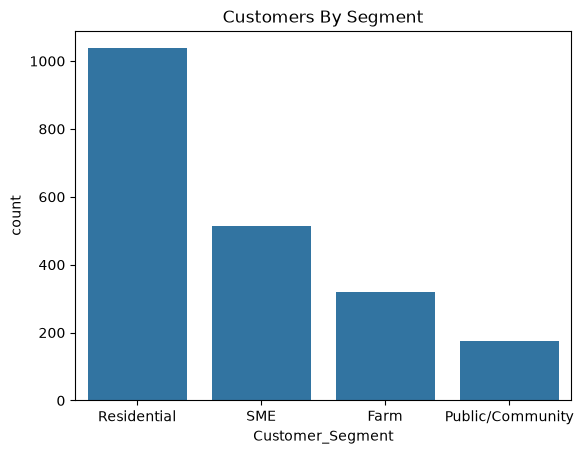

In [331]:
sns.countplot(
    data=df,
    x="Customer_Segment")

plt.title("Customers By Segment")

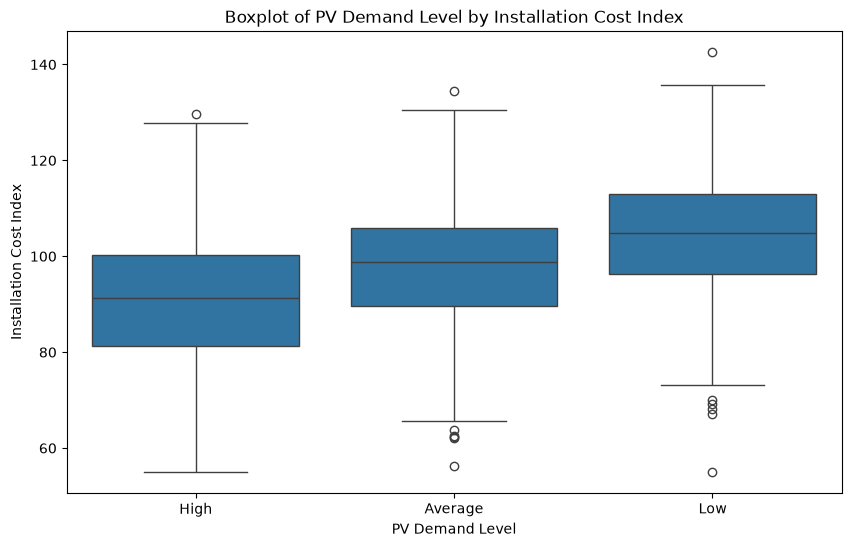

In [332]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["PV_Demand_Level"],
    y= df["Install_Cost_Ind"]
)
   

plt.title("Boxplot of PV Demand Level by Installation Cost Index" )
plt.xlabel("PV Demand Level")
plt.ylabel("Installation Cost Index")

plt.show()

Show analysis of the Target - PV_Demand_Level

In [333]:
df["PV_Demand_Level"].value_counts(normalize=True)

PV_Demand_Level
Average    0.476773
Low        0.263081
High       0.260147
Name: proportion, dtype: float64

Text(0.5, 1.0, 'PV Demand Level')

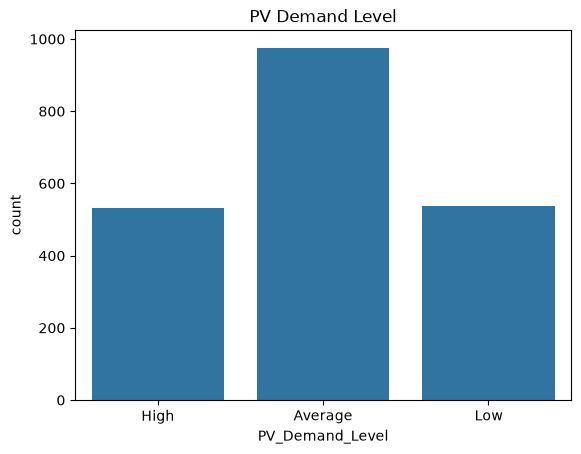

In [334]:
sns.countplot(
    data=df,
    x="PV_Demand_Level")

plt.title("PV Demand Level")

The PV_Demand_Level is the Target class.  

The above chart shows it's reasonably balanced, reducing the chances of model bias during the Machine Learning Section.


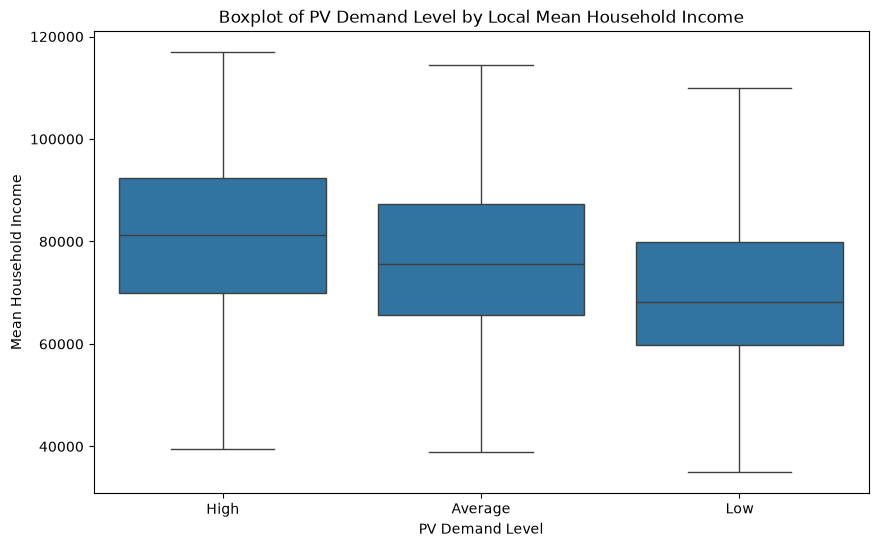

In [335]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["PV_Demand_Level"],
    y= df["Local_Mean_Income"]
)
   

plt.title("Boxplot of PV Demand Level by Local Mean Household Income" )
plt.xlabel("PV Demand Level")
plt.ylabel("Mean Household Income")

plt.show()

The above Boxplot suggests that higher Local Mean Household Income is associated with a higher PV demand level

<Axes: xlabel='Local_Mean_Income', ylabel='Proj_PV_Install_Capacity'>

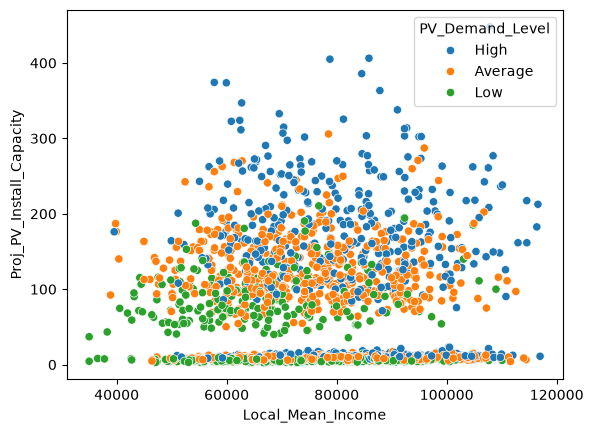

In [336]:
sns.scatterplot(
    data = df,
    x= "Local_Mean_Income",
    y = "Proj_PV_Install_Capacity",
    hue = "PV_Demand_Level"
)

The scatterplot does not suggest a strong relationship between Local Mean Household income and Projected PV Installation Capacity.

However some separation is evident.  High demand observations tend to be associated with larger projected installation capacities.  
    

In [337]:
# create a pivot table
pivot = pd.pivot_table (
    df,
    values="Install_Cost_Ind",
    index="PV_Demand_Level",
    columns="Customer_Segment",
    aggfunc="count",
    margins=True,
    margins_name="Total"
)
pivot

Customer_Segment,Farm,Public/Community,Residential,SME,Total
PV_Demand_Level,,,,,
Average,145,83,508,239,975
High,123,57,195,157,532
Low,51,35,334,118,538
Total,319,175,1037,514,2045


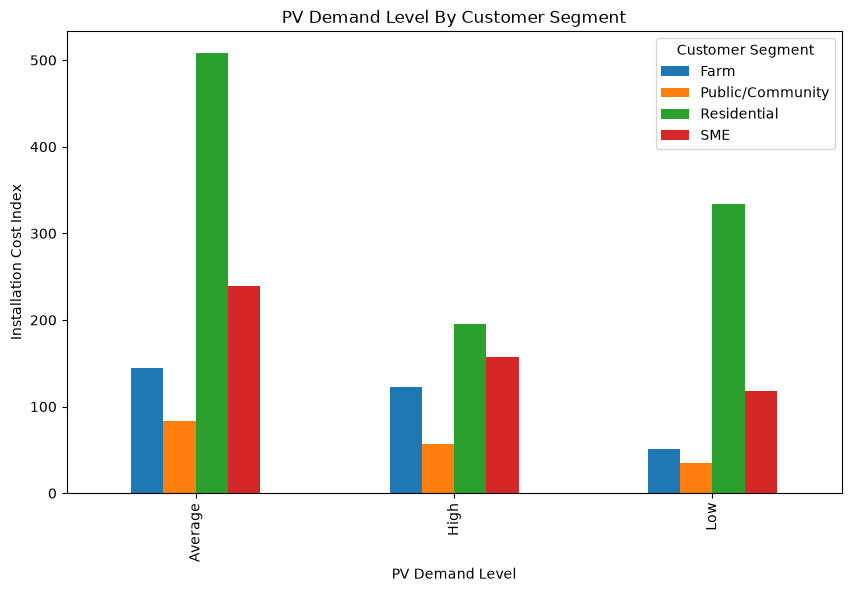

In [338]:
pivot_chart = pivot.drop(
    index="Total",
    errors="ignore").drop(
    columns="Total",
    errors="ignore")

pivot_chart.plot(
    kind="bar",
    figsize=(10,6))

plt.title("PV Demand Level By Customer Segment")
plt.xlabel("PV Demand Level")
plt.ylabel("Installation Cost Index")
plt.legend(title="Customer Segment")

plt.show()

In [339]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,Forecast_Year,Local_Mean_Income,Electric_Cost,Solar_Resource,Site_Suitability,Grid_Accessibility,Grant_Support,Install_Cost_Ind,Planning_Constraint_Ind,Proj_PV_Install_Capacity,PV_Demand_Code
Forecast_Year,1.000000,0.245808,-0.338377,0.025551,-0.021478,-0.002520,0.003495,-0.540516,-0.018376,0.169729,0.299964
Local_Mean_Income,0.245808,1.000000,-0.039319,0.178917,-0.052594,0.517120,-0.067280,-0.100929,0.507425,0.008457,0.284447
Electric_Cost,-0.338377,-0.039319,1.000000,0.006256,0.021309,0.048385,-0.022018,0.172272,0.044137,0.006653,0.124976
Solar_Resource,0.025551,0.178917,0.006256,1.000000,0.003758,0.215207,0.015263,0.029922,0.137650,0.066991,0.334746
Site_Suitability,-0.021478,-0.052594,0.021309,0.003758,1.000000,-0.121799,0.274739,-0.045084,-0.103430,0.476005,0.342479
Grid_Accessibility,-0.002520,0.517120,0.048385,0.215207,-0.121799,1.000000,-0.078993,0.037244,0.441156,-0.063852,0.277123
Grant_Support,0.003495,-0.067280,-0.022018,0.015263,0.274739,-0.078993,1.000000,-0.067805,-0.098495,0.562379,0.162116
Install_Cost_Ind,-0.540516,-0.100929,0.172272,0.029922,-0.045084,0.037244,-0.067805,1.000000,0.034300,-0.229489,-0.347775
Planning_Constraint_Ind,-0.018376,0.507425,0.044137,0.137650,-0.103430,0.441156,-0.098495,0.034300,1.000000,-0.137912,-0.082655
Proj_PV_Install_Capacity,0.169729,0.008457,0.006653,0.066991,0.476005,-0.063852,0.562379,-0.229489,-0.137912,1.000000,0.382981


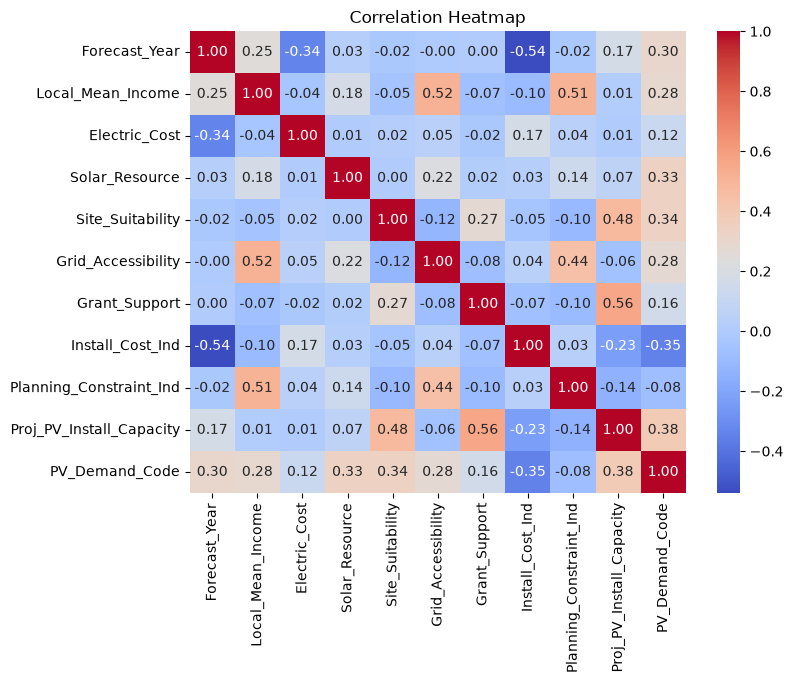

In [340]:
# create a seaborn heatmap
plt.figure(figsize=(8,6) )

sns.heatmap(
    corr_matrix,  
    annot=True,   
    cmap="coolwarm",  
    fmt=".2f" )      

plt.title("Correlation Heatmap")

plt.show()

From the above correaltion heatmap, we can see positive correlation between Local_Mean_income (r=0.52) and Grid_Accessibility.

Our Target Variable PV_Demand_Code, which is the numeric option for PV_Demand_Level, shows a moderate relationship (r=0.38) to Proj_PV_Install_Capacity, suggesting that larger installations are associated with higher demand levels.
    
We also see Grant_Support shows a moderate positive relationship (r=0.55) and Projected_PV_Installation_Capacity, suggesting that larger grants may encourage larger-scale solar installations.

Site_Suitability also provides a moderate positive relationship (r=0.48) to Projected_PV_Installation_Capacity, suggesting that more suitable locations will have a higher installation capacity

Forecast_Year shows a moderate negative relationship (r= -0.55) with Installation_Cost_Index, this suggests that costs are projected to decrease over time.  

Installation_Cost_Index also shows a weak negative relationship (r= -0.24) with Projected_PV_Installation_Capacity, suggesting that higher costs may reduce the size of of PV installations.

    

    

In [341]:
corr_matrix["PV_Demand_Code"]

Forecast_Year               0.299964
Local_Mean_Income           0.284447
Electric_Cost               0.124976
Solar_Resource              0.334746
Site_Suitability            0.342479
Grid_Accessibility          0.277123
Grant_Support               0.162116
Install_Cost_Ind           -0.347775
Planning_Constraint_Ind    -0.082655
Proj_PV_Install_Capacity    0.382981
PV_Demand_Code              1.000000
Name: PV_Demand_Code, dtype: float64

We can see also from the corr_matrix for PV_Demand_Code that Site_Suitability has a moderate correlation (r=0.34), suggesting more suitable locations tend to have a higher demand level.

Solar_Resource has a moderate correlation (r=0.33), suggestion that areas of good Solar resources are more likely to have higher demand for solar PV installations.  

Forecast_Year has demonstrated a moderate relationship of (r=0.299) indicating that PV Demand is expected to rise in the years ahead.  

Installation_Cost has shown a negative relationship (r = -0.34) , suggesting that higher costs may reduce PV Demand levels.  

From the correlation matrix of PV_Code, there is no strong relationship, suggesting a number of factors may decide PV demand levels, rather than a single predictor.

    

In [342]:
from scipy.stats import linregress

In [343]:
x = df["Proj_PV_Install_Capacity"]
y = df["Grant_Support"]

slope, intercept, r, p, stderr = linregress(x,y)

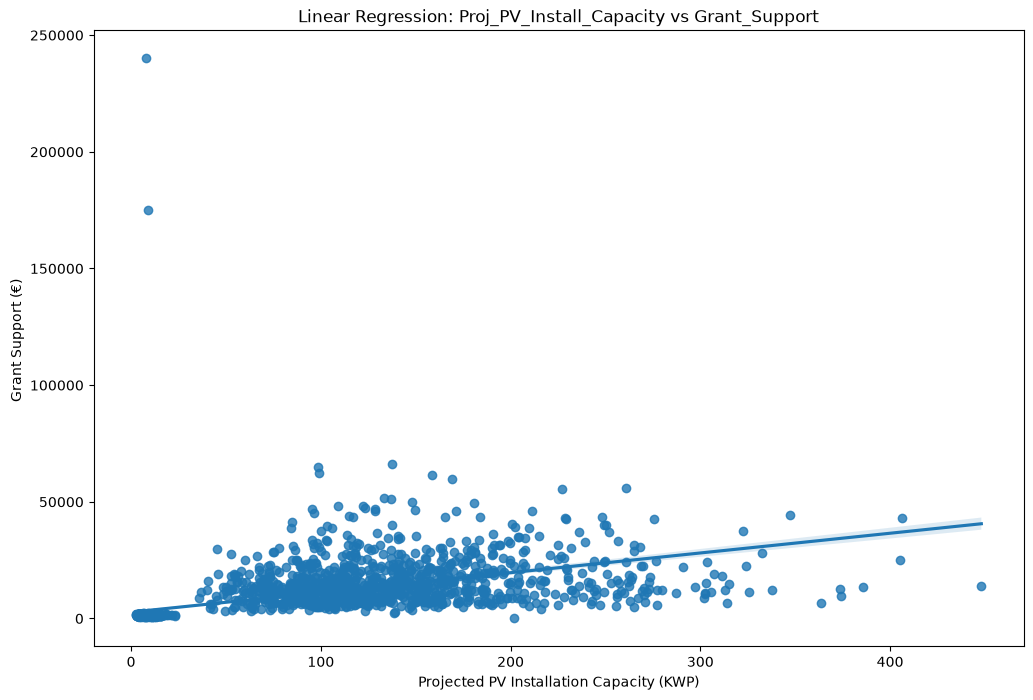

In [344]:

plt.figure(figsize=(12,8))


sns.regplot(
    x = "Proj_PV_Install_Capacity",
    y = "Grant_Support",
    data = df
)

plt.title("Linear Regression: Proj_PV_Install_Capacity vs Grant_Support")
plt.xlabel("Projected PV Installation Capacity (KWP)" )
plt.ylabel("Grant Support (€) ")

plt.show()

Grant Support provided the strongest relationship with Projected_PV_Installation_Capacity (r = 0.56).  

The regression line indicates that larger grant allocations are associated with larger PV installations.  This relationship suggests that financial incentives may be a driving factor in take up of PV installations.

    

Create a Distribution Chart of Local_Mean_Income and check normality

In [345]:
from scipy import stats 
from scipy.stats import norm # for normality test 

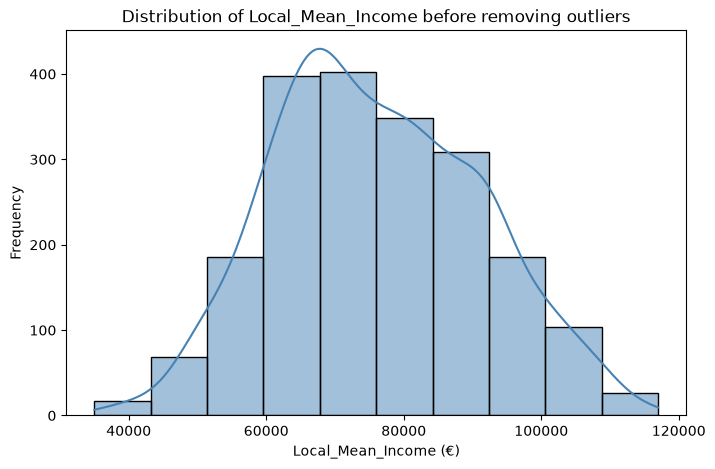

In [346]:
plt.figure(figsize=(8,5) )

sns.histplot(
    data=df,
    x="Local_Mean_Income",
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Local_Mean_Income before removing outliers")
plt.xlabel("Local_Mean_Income (€)")
plt.ylabel("Frequency")


plt.show()

#### Check Normality (using Shapiro_Wilk_test) 

In [347]:
stat, p_value = stats.shapiro(df["Local_Mean_Income"])

print(stat,p_value)

0.9920214876666434 3.896977231217994e-09


In [348]:
if p_value >= 0.05:
    print("Sample appears to be normally distributed.")
else:
    print("Sample does not appear to be normally distributed.")
    

Sample does not appear to be normally distributed.


Drop Outliers in Local_Mean_Income using the IQR Method

In [349]:
Before_Removal = len(df["Local_Mean_Income"])
print(Before_Removal)

2045


In [350]:
Q1 = df["Local_Mean_Income"].quantile(0.25)
Q3 = df["Local_Mean_Income"].quantile(0.75)
IQR = Q3 - Q1
print("Q1= " , Q1)
print("Q3= " , Q3)
print("IQR= " , IQR)

Q1=  64913.28
Q3=  87283.49
IQR=  22370.210000000006


In [351]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("lower_bound =  " , lower_bound)
print("upper_bound =  " , upper_bound)

lower_bound =   31357.96499999999
upper_bound =   120838.80500000002


Remove the lower and upper bounds

In [352]:
df = df[
    (df["Local_Mean_Income"] >= lower_bound) &
     (df["Local_Mean_Income"] <= upper_bound)
      ]

In [353]:
df["Local_Mean_Income"].describe()

count      2045.000000
mean      76058.583614
std       15069.145904
min       35000.000000
25%       64913.280000
50%       74850.580000
75%       87283.490000
max      116976.500000
Name: Local_Mean_Income, dtype: float64

In [354]:
After_Removal = len(df["Local_Mean_Income"])
print(After_Removal)

2045


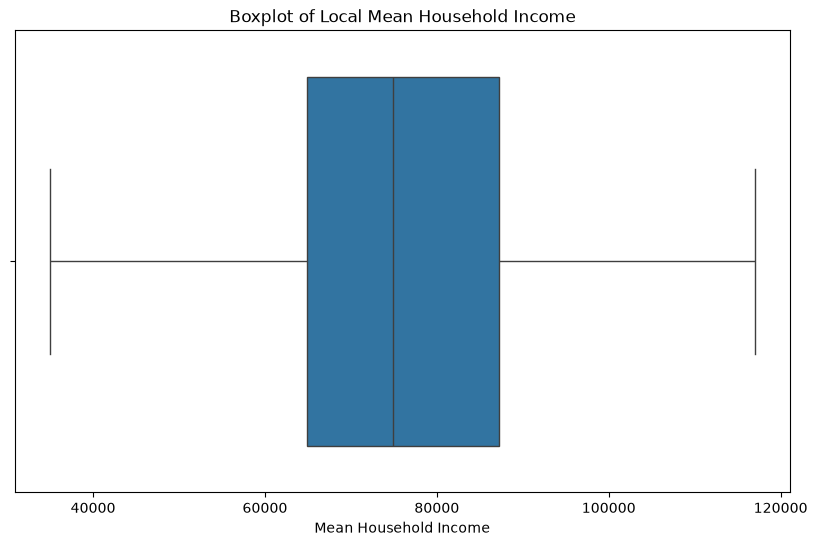

In [355]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["Local_Mean_Income"]
)
   

plt.title("Boxplot of Local Mean Household Income" )

plt.xlabel("Mean Household Income")

plt.show()

A histogram was developed to assess the distribution of Local_Mean_Income, showing no substantial evidence of extreme outliers.

The Shapiro-Wilk Test was performed to assess normality.  The results suggested that the sample did not appear normally distributed. 
    
In this case, the IQR method was applied to identify potential outliers with Local_Mean_Income.

However, no observations fell outside the lower and upper IQR thresholds.  This suggests that i had already addressed the outliers earlier in data cleaning stage and no further removal was required. 

The above Boxplot shows no extreme outliers outside the IQR Thresholds, which were dealt with at data cleaning stage. 

Create a Distribution Chart of Grant_Support and check normality

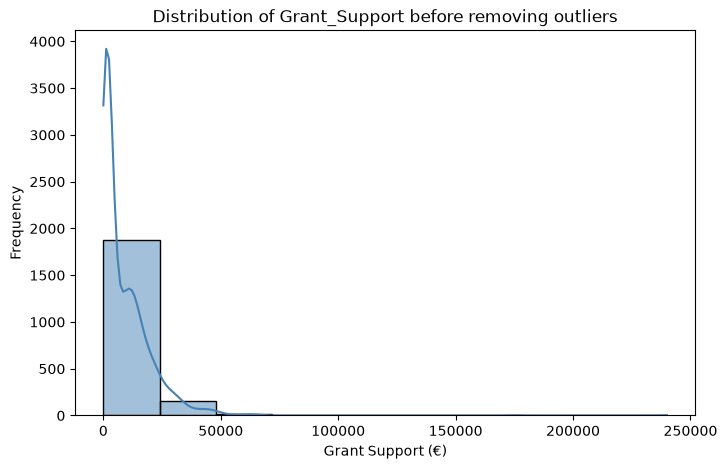

In [356]:
plt.figure(figsize=(8,5) )

sns.histplot(
    data=df,
    x="Grant_Support",
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Grant_Support before removing outliers")
plt.xlabel("Grant Support (€)")
plt.ylabel("Frequency")


plt.show()

#### Check Normality (using Shapiro_Wilk_test) 

In [357]:
stat, p_value = stats.shapiro(df["Grant_Support"])

print(stat,p_value)

0.6269190424876446 6.625714188723199e-55


In [358]:
if p_value >= 0.05:
    print("Sample appears to be normally distributed.")
else:
    print("Sample does not appear to be normally distributed.")
   

Sample does not appear to be normally distributed.


#### Create a Boxplot showing the Grant_Support

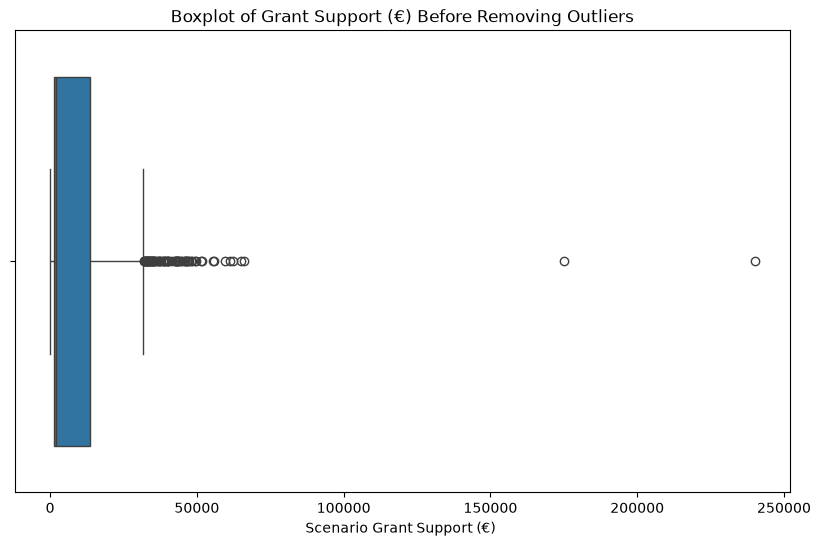

In [359]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["Grant_Support"]
)
   

plt.title("Boxplot of Grant Support (€) Before Removing Outliers" )

plt.xlabel("Scenario Grant Support (€) ")

plt.show()

In [360]:
Before_Removal2 = len(df["Grant_Support"])
print(Before_Removal2)

2045


In [361]:
Q1 = df["Grant_Support"].quantile(0.25)
Q3 = df["Grant_Support"].quantile(0.75)
IQR = Q3 - Q1
print("Q1= " , Q1)
print("Q3= " , Q3)
print("IQR= " , IQR)

Q1=  1440.74
Q3=  13600.01
IQR=  12159.27


In [362]:
lower_bound2 = Q1 - (1.5 * IQR)
upper_bound2 = Q3 + (1.5 * IQR)

print("lower_bound =  " , lower_bound2)
print("upper_bound =  " , upper_bound2)

lower_bound =   -16798.164999999997
upper_bound =   31838.915


Remove the lower and upper bounds

In [363]:
df = df[
    (df["Grant_Support"] >= lower_bound2) &
     (df["Grant_Support"] <= upper_bound2)
      ]

In [364]:
df["Grant_Support"].describe()

count     1971.000000
mean      7528.715961
std       7839.655217
min          0.000000
25%       1430.000000
50%       1903.040000
75%      12369.040000
max      31642.600000
Name: Grant_Support, dtype: float64

In [365]:
After_Removal2 = len(df["Grant_Support"])
print(After_Removal2)

1971


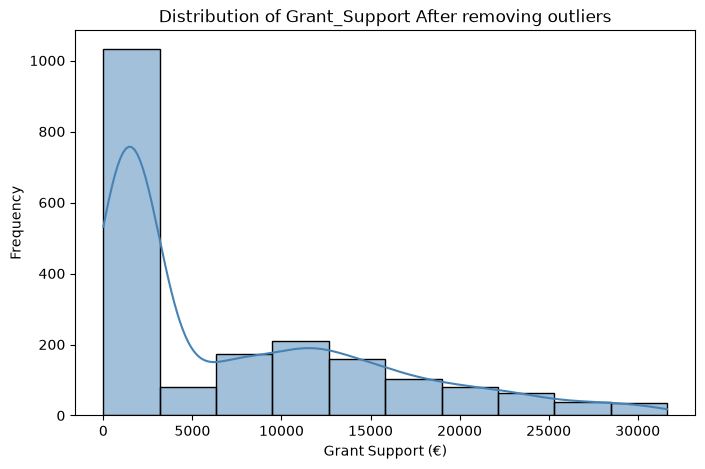

In [366]:
plt.figure(figsize=(8,5) )

sns.histplot(
    data=df,
    x="Grant_Support",
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Grant_Support After removing outliers")
plt.xlabel("Grant Support (€)")
plt.ylabel("Frequency")


plt.show()

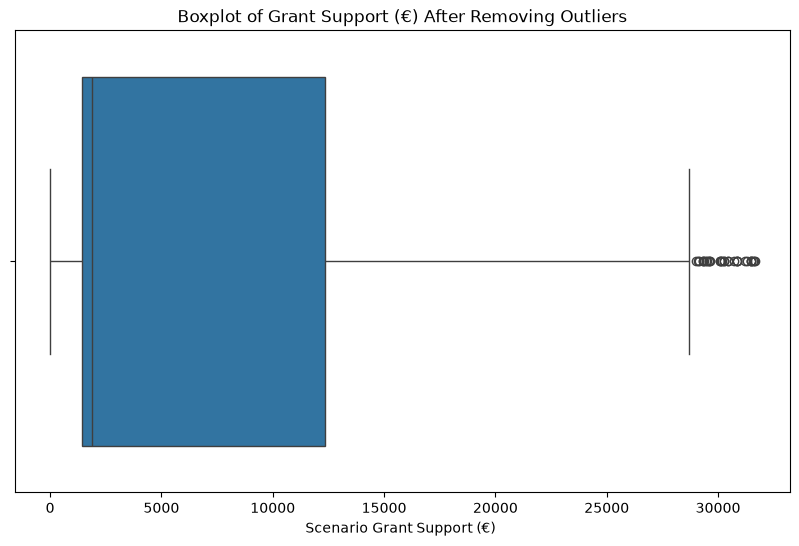

In [367]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["Grant_Support"]
)
   

plt.title("Boxplot of Grant Support (€) After Removing Outliers" )

plt.xlabel("Scenario Grant Support (€) ")

plt.show()

Outlier Analysis was conducted using the IQR method on Scenario Grant Support & Local Mean Household income. However prior to this, at data cleaning stage, out of range data was imputed.  

Values were modified if they held invalid observations or values outside the range.  
    
Values were removed if no Forecast_Year was present.  As such, The Local mean Household imcome found no observations to remove when conducting the IQR method.    

Carry out Hypothesis Tests 
1. Does Household income differ by PV_Demand_Level
2. Does Proj_PV_Installation_Capacity differ by PV_Demand_Level
3. 